In [214]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor  
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error 
from sklearn.model_selection import train_test_split
from scipy.special import expit


In [215]:
# [ 도미 ]
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0,
33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0,
610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]

# [ 빙어 ]
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [216]:
total_length = bream_length + smelt_length
total_weight = bream_weight + smelt_weight

In [217]:
print(len(bream_length))
print(len(smelt_length))

35
14


In [218]:
label = ['bream']*35+['smelt']*14
# label

data = [[l,w] for l, w in zip(total_length, total_weight)]
# data

In [219]:
train_data, test_data, train_label, test_label = train_test_split(data,label)


In [220]:
data = np.column_stack((total_length, total_weight))
label = np.concatenate((np.ones(35),np.zeros(14)))

In [221]:
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [222]:
lr = LogisticRegression()
lr.fit(train_scaled, train_label)

predict = lr.predict(test_scaled)
print('예측 생선 :', predict)

print('train 정확도 :', lr.score(train_scaled, train_label))
print('test 정확도 :', lr.score(test_scaled, test_label))

예측 생선 : ['smelt' 'bream' 'bream' 'bream' 'smelt' 'bream' 'smelt' 'bream' 'bream'
 'bream' 'bream' 'bream' 'bream']
train 정확도 : 1.0
test 정확도 : 1.0


In [223]:
lr.predict_proba(test_scaled)[:5]

array([[0.11354134, 0.88645866],
       [0.99891653, 0.00108347],
       [0.99045134, 0.00954866],
       [0.84130593, 0.15869407],
       [0.09316524, 0.90683476]])

In [224]:
decision = lr.decision_function(test_scaled[:5])
np.round(decision,decimals=4)
expit(decision)

array([0.88645866, 0.00108347, 0.00954866, 0.15869407, 0.90683476])

In [225]:
new = [[21,90]]
new = [[25,150]]

In [226]:
in_data = input('생선의 길이(cm), 무게(g)를 입력하세요: 예)21,90')
in_data = '21,9'
in_data = in_data.split(',')
in_data2 = list(map(float, in_data))
in_data2

[21.0, 9.0]

In [227]:
new_scaled = ss.transform ([[21,90]])
new2_scaled = ss.transform ([[25,150]])

In [228]:
result = lr.predict(new_scaled)
result2 = lr.predict(new2_scaled)
result[0]
p_result = lr.predict_proba(new_scaled)
p_result2 = lr.predict_proba(new2_scaled)
p_result[0][0]
print(f'예측생선 : {result[0]} / ({p_result[0][1]*100:.2f} %)')
print(f'예측생선 : {result2[0]} / ({p_result2[0][0]*100:.2f} %)')

예측생선 : smelt / (58.08 %)
예측생선 : bream / (65.13 %)


In [233]:
train_scaled[:,0]

array([ 0.54347911, -1.39132847,  0.9383378 ,  0.69155112, -0.10803772,
       -1.45055727,  0.69155112, -1.20377059, -1.43081434,  0.34604977,
        1.03705248,  0.83962313, -0.01919452,  0.83962313,  1.18512448,
       -1.64798662, -1.56901488,  0.34604977,  0.64219379,  0.49412178,
        0.41515004,  0.44476444,  0.74090846,  0.79026579,  0.54347911,
        0.44476444,  0.74090846, -1.4110714 ,  1.18512448, -1.49991461,
       -1.52952901, -1.13467032,  0.2473351 , -1.57888635,  0.54347911,
        1.28383916])

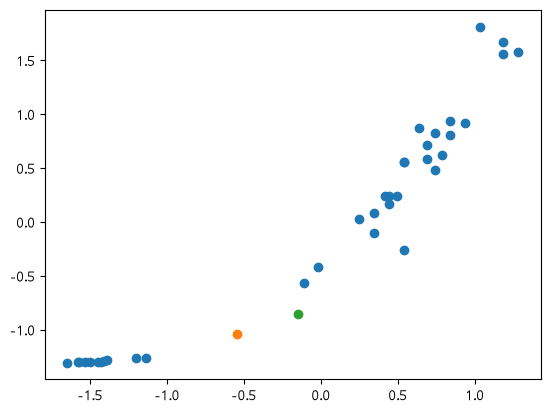

In [229]:
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(new_scaled[:,0],new_scaled[:,1])
plt.scatter(new2_scaled[:,0],new2_scaled[:,1])
plt.show()

In [235]:
lr.predict_proba(test_scaled[:5])

array([[0.11354134, 0.88645866],
       [0.99891653, 0.00108347],
       [0.99045134, 0.00954866],
       [0.84130593, 0.15869407],
       [0.09316524, 0.90683476]])

In [236]:
decisions = lr.decision_function(test_scaled[:5])
np.round(decisions,decimals=4)
expit(decisions)

array([0.88645866, 0.00108347, 0.00954866, 0.15869407, 0.90683476])

In [237]:
print('train정확도 : ',lr.score(train_scaled,train_label))
print('test정확도 : ',lr.score(test_scaled,test_label))

train정확도 :  1.0
test정확도 :  1.0
